In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.patches as mpatches
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import matplotlib.lines as mlines
import folium 
from shapely.geometry import box
import requests
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from shapely.geometry import box
import requests
import os
import warnings
warnings.filterwarnings("ignore")

print("All modules succesfully imported")
import warnings
warnings.filterwarnings("ignore")

print("All modules succesfully imported")

All modules succesfully imported
All modules succesfully imported


Creating a path for our data so that it can be easily accessed

In [70]:
DATA = "C:/Users/TEDSON/chimaliro-schoolsite-accessibility/data"

ta_path = f"{DATA}/mw_ta.geojson"
small_roads_path = f"{DATA}/thyolo_roads.geojson"

ta_raw = gpd.read_file(ta_path)
print(ta_raw.columns.tolist) #Checking the columns in the ta_raw GeoDataFrame

<bound method IndexOpsMixin.tolist of Index(['AREA', 'PERIMETER', 'MW_DIST_BN', 'MW_DIST__1', 'TA_NAME', 'geometry'], dtype='str')>


Loading shape files to be used in the project

In [71]:
#load the ta boundary and filter for chimaliro
print("Loading TA boundary...")
ta_raw = gpd.read_file(ta_path)
name_col = "TA_NAME"
ta = ta_raw[ta_raw[name_col].astype(str).str.upper().str.contains("CHIMALIRO", na=False)].copy()
print(f"found {len(ta)} TA feature(s) for Chimaliro")


print("\nloading data and fixing CRS...")
prot_raw = gpd.read_file(f"{DATA}/mw_protected_areas.geojson")
roads_small = gpd.read_file(small_roads_path)
sch_mw = gpd.read_file(f"{DATA}/mw_primary_schools.geojson")

UTM_CRS = "EPSG:32736"  # UTM Zone 36N

ta = ta.to_crs(UTM_CRS)
prot_ta = gpd.clip(prot_raw.to_crs(UTM_CRS), ta)

roads_ta = roads_small.to_crs(UTM_CRS)


school_ta = gpd.clip(sch_mw.to_crs(UTM_CRS), ta)


print("\n ...Cleaned Data check...")
print(f"Protected areas within TA: {len(prot_ta)}")
print(f"Roads within TA: {len(roads_ta)}")
print(f"Schools within TA: {len(school_ta)}") 

Loading TA boundary...
found 1 TA feature(s) for Chimaliro

loading data and fixing CRS...

 ...Cleaned Data check...
Protected areas within TA: 0
Roads within TA: 409
Schools within TA: 29


In [72]:
print(school_ta.head())

                  X             Y District  EMIS_Numbe             School_Nam  \
4968  730615.129434  8.227533e+06   Thyolo    502367.0                Nasonia   
4956  724398.360960  8.232746e+06   Thyolo    502245.0         Namaona School   
4934  746546.273699  8.224969e+06   Thyolo    501632.0         Matumbo School   
5044  747005.108052  8.229043e+06   Thyolo    505060.0  Ennockie View Academy   
4924  747735.297942  8.229648e+06   Thyolo    501370.0        Luchenza School   

         X_Coordina    Y_Coordina  male_stude  female_stu            Type  \
4968  730639.153976  8.227510e+06        96.0       117.0  Primary school   
4956  724422.386907  8.232723e+06       623.0       605.0  Primary school   
4934  746570.296030  8.224945e+06       277.0       289.0  Primary school   
5044  747029.130920  8.229020e+06         0.0         0.0  Primary school   
4924  747759.320814  8.229625e+06      1135.0      1246.0  Primary school   

         Long      Lat  No_of_Teac     r          

In [73]:
print(school_ta.columns.tolist())

['X', 'Y', 'District', 'EMIS_Numbe', 'School_Nam', 'X_Coordina', 'Y_Coordina', 'male_stude', 'female_stu', 'Type', 'Long', 'Lat', 'No_of_Teac', 'r', 'geometry']


Lets visualize our imported data on a map

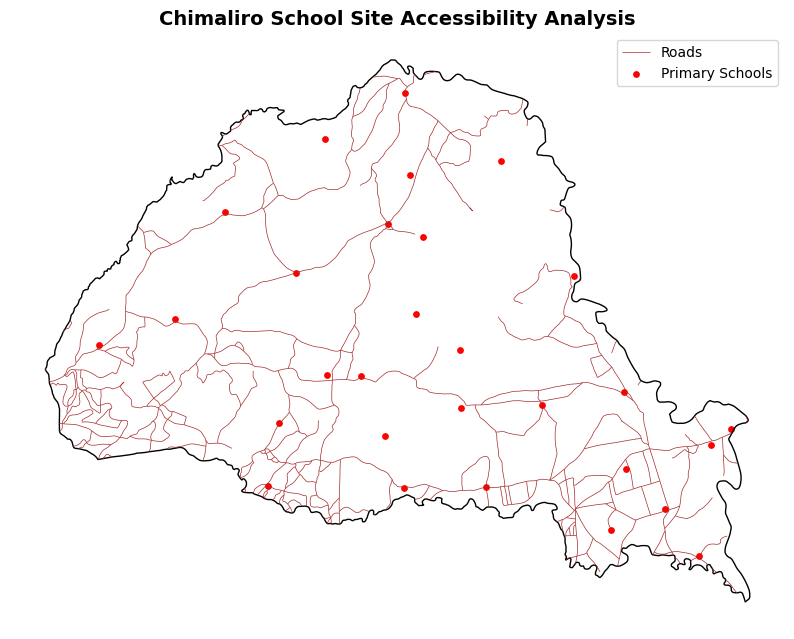

In [74]:
fig, ax = plt.subplots(figsize=(10, 9))

# Plot Chimaliro TA boundary
ta.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1
)

#ploting roads 
roads_ta.plot(
    ax=ax,
    color="brown",
    linewidth=0.5,
    label="Roads"
)

# Plot primary schools
school_ta.plot(
    ax=ax,
    color="red",
    markersize=15,
    label="Primary Schools"
)

#ploting protected areas
prot_ta.plot(
    ax=ax,
    color="green",
    alpha=0.5,
    label="Protected Areas"
    )



ax.set_title("Chimaliro School Site Accessibility Analysis", fontsize=14, fontweight="bold")

ax.legend()
ax.set_axis_off()

plt.show()

After visualising the data on a separate canvas , analysis should follow which will include buffering , exclusion and intersecting all layers to come up with a final map.

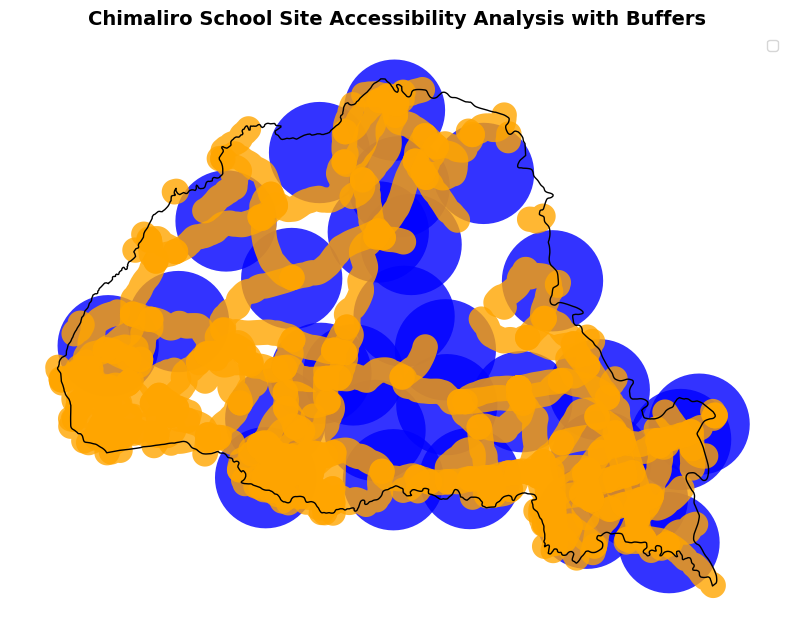

In [75]:
School_buffer = school_ta.geometry.buffer(2000)  # Buffer of 2 km

roads_within_buffer = roads_ta.geometry.buffer(500)  # Buffer of 500 m


fig , ax = plt.subplots(figsize=(10, 9))


ta.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1
)


School_buffer.plot(
    ax=ax,
    color="blue",
    alpha=0.8,
    label="School Buffer (2 km)"
)

roads_within_buffer.plot(
    ax=ax,
    color="orange",
    alpha=0.8,
    label="Roads Buffer (500 m)"
)

ax.set_title("Chimaliro School Site Accessibility Analysis with Buffers", fontsize=14, fontweight="bold")

ax.set_axis_off()
ax.legend()
plt.show()

After doing buffering lets do exclusion and suitable analysis

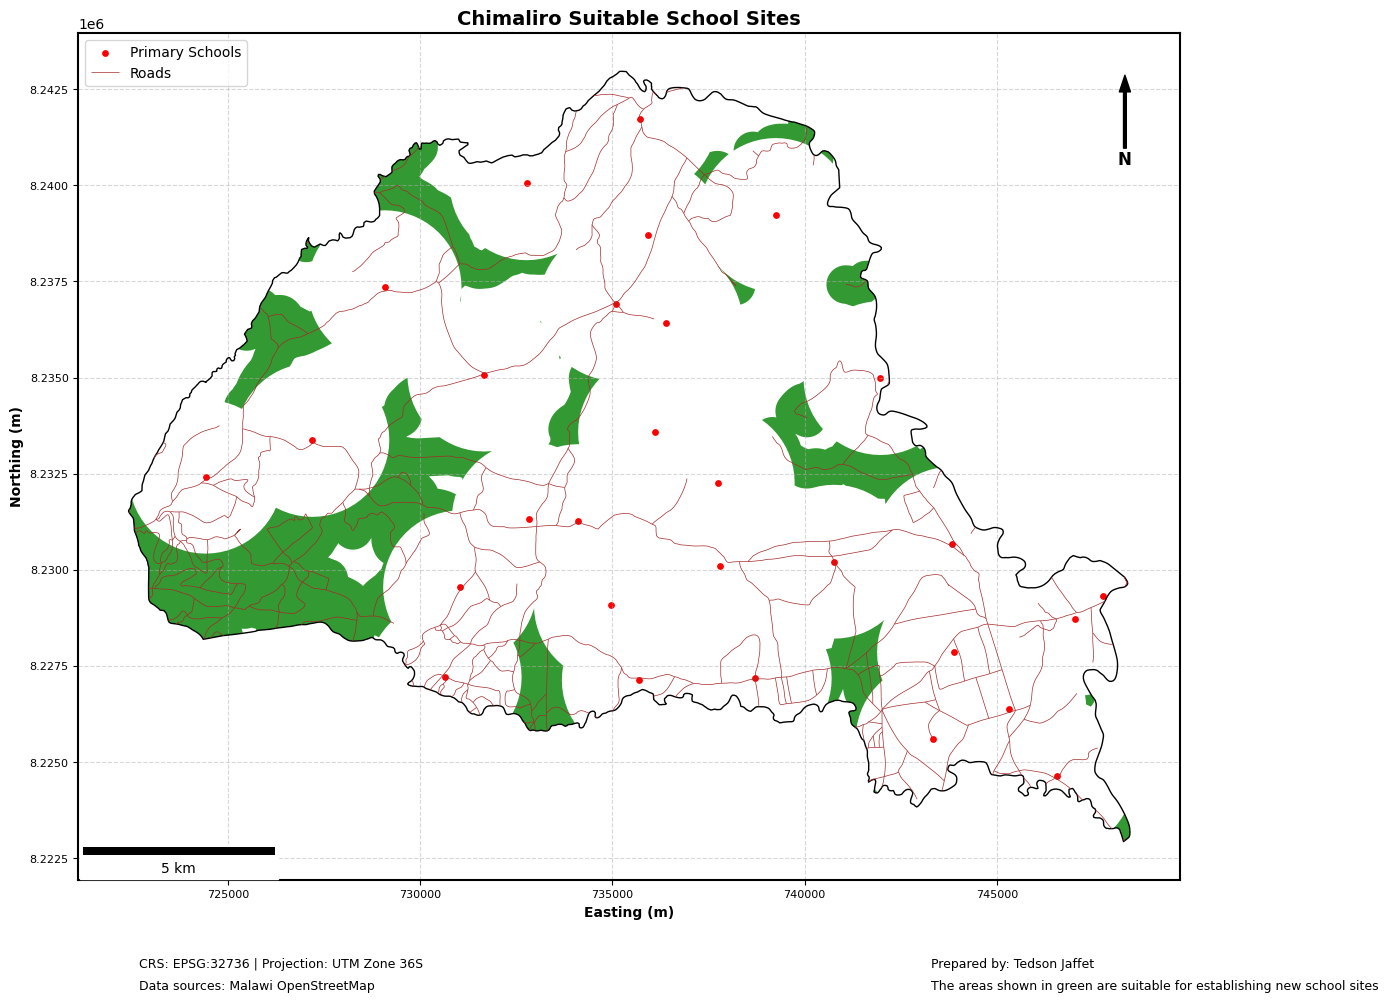

In [84]:
#convert the buffers to GeoDataFrames
school_buffer_gdf = gpd.GeoDataFrame(geometry=School_buffer, crs=UTM_CRS)
roads_buffer_gdf = gpd.GeoDataFrame(geometry=roads_within_buffer, crs=UTM_CRS)


#disolve the buffers to create single geometries
school_buffer_dissolved = school_buffer_gdf.dissolve()
roads_buffer_dissolved = roads_buffer_gdf.dissolve()


#road accessible within road buffer
road_accessible =  gpd.overlay(
    ta, 
    roads_buffer_dissolved, 
    how='intersection'
)

#exclude areas that are within the school buffer
accessible_areas = gpd.overlay(
    road_accessible,
    school_buffer_gdf,
    how='difference'
)

#suitable school sites
suitable_sites = gpd.overlay(
    accessible_areas,
    prot_ta,
    how='difference'
)

fig, ax = plt.subplots(figsize=(12, 11))

ta.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1
)

suitable_sites.plot(
    ax=ax,
    color="green",
    alpha=0.8,
    label="Suitable School Sites"
)


school_ta.plot(
    ax=ax,
    color="red",
    markersize=15,
    label="Primary Schools"
)

roads_ta.plot(
    ax=ax,
    color="brown",
    linewidth=0.5,
    label="Roads"
)

ax.annotate(
    "N",
    xy=(0.95, 0.95),
    xytext=(0.95, 0.85),
    xycoords="axes fraction",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    arrowprops=dict(facecolor="black", width=2, headwidth=8)
)

Scalebar = ScaleBar(
    dx=1,
    units="m",
    location="lower left",
    length_fraction=0.2,
)

ax.add_artist(Scalebar)

ax.tick_params(
    axis="both",
    labelsize=8,
)

ax.set_xlabel("Easting (m)", fontsize=10, fontweight="bold")
ax.set_ylabel("Northing (m)", fontsize=10, fontweight="bold")

ax.grid(
    True,
    linestyle="--",
    alpha=0.5,
)

#map information

fig.text(
    0.12, 0.035,
    "CRS: EPSG:32736 | Projection: UTM Zone 36S",
    fontsize=9
)

fig.text(
    0.12, 0.015,
    "Data sources: Malawi OpenStreetMap",
    fontsize=9
)

fig.text(
    0.78, 0.035,
    "Prepared by: Tedson Jaffet",
    fontsize=9
)
fig.text(
    0.78, 0.015,
    "The areas shown in green are suitable for establishing new school sites",
    fontsize=9
)


for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)


ax.set_title("Chimaliro Suitable School Sites", fontsize=14, fontweight="bold")
ax.set_axis_on()
ax.legend()
plt.tight_layout()
plt.show()


In [77]:
PATH = "C:/Users/TEDSON/chimaliro-schoolsite-accessibility/outputs"

saved_map_path = f"{PATH}/chimaliro_suitable_school_sites.png"

fig.savefig(saved_map_path, dpi=300, bbox_inches='tight')

Creating An interative map using folium and html

In [86]:
!pip install folium

import folium
from folium.plugins import Fullscreen, MeasureControl, MiniMap



Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [ ]:
# Calculate area in hectares using projected data

suitable_sites["Area_ha"] = (
    suitable_sites.geometry.area / 10000
)


# Check the results
print(suitable_sites.columns)

suitable_sites.head()

# Convert layers to WGS 84

ta_web = ta.to_crs(epsg=4326)

schools_web = school_ta.to_crs(epsg=4326)

roads_web = roads_ta.to_crs(epsg=4326)

protected_web = prot_ta.to_crs(epsg=4326)

suitable_web = suitable_sites.to_crs(epsg=4326)


# Calculate the centre using projected coordinates

centre_projected = ta.geometry.union_all().centroid

# Convert the centre to geographic coordinates

centre_web = gpd.GeoSeries(
    [centre_projected],
    crs=ta.crs
).to_crs(epsg=4326)

latitude = centre_web.iloc[0].y

longitude = centre_web.iloc[0].x

#This Line creates a folium map centered on the calculated latitude and longitude, with a zoom level of 12, using OpenStreetMap tiles, and enabling control scale for better navigation.
m = folium.Map(
    location=[latitude, longitude],
    zoom_start=12,
    tiles="OpenStreetMap",
    control_scale=True
)

#adding chimaliro boundary
folium.GeoJson(
    ta_web,
    name="Chimaliro Boundary",
    style_function=lambda feature: {
        "color": "black",
        "weight": 2,
        "fillOpacity": 0
    }
).add_to(m)

#adding suitable school sites

folium.GeoJson(
    suitable_web,
    name="Suitable Areas",
    style_function=lambda feature: {
        "fillColor": "green",
        "color": "darkgreen",
        "weight": 1,
        "fillOpacity": 0.6
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["Area_ha"],
        aliases=["Suitable Area (ha):"],
        localize=True
    )
).add_to(m)

#adding existing schools
school_layer = folium.FeatureGroup(
    name="Existing Schools"
)

folium.GeoJson(
    schools_web,
    tooltip=folium.GeoJsonTooltip(
        fields=[school_ta.columns[school_ta.columns != "geometry"][0]],
        aliases=["School Information:"]
    ),
    marker=folium.CircleMarker(
        radius=5,
        color="red",
        fill=True,
        fill_color="red",
        fill_opacity=1
    )
).add_to(school_layer)

school_layer.add_to(m)

#adding roads
folium.GeoJson(
    roads_web,
    name="Road Network",
    style_function=lambda feature: {
        "color": "orange",
        "weight": 2
    }
).add_to(m)

#adding protected areas
folium.GeoJson(
    protected_web,
    name="Protected Areas",
    style_function=lambda feature: {
        "fillColor": "grey",
        "color": "black",
        "weight": 1,
        "fillOpacity": 0.5
    }
).add_to(m)

#adding map controls
folium.LayerControl(
    position="topright",
    collapsed=False
).add_to(m)

Fullscreen(
    position="topleft"
).add_to(m)

MeasureControl(
    position="topleft",
    primary_length_unit="kilometers",
    secondary_length_unit="meters",
    primary_area_unit="hectares"
).add_to(m)

#minmap
MiniMap(
    toggle_display=True
).add_to(m)

m #display the map

#saving the map as an HTML file
interactive_map_path = f"{PATH}/interactive_chimaliro_school_suitability.html"

m.save(interactive_map_path)



print("Interactive map successfully saved!")

print(interactive_map_path)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (927452805.py, line 4)